# ETH/USDT 动态网格回测：XGBoost 门控 vs 无门控 vs Buy&Hold

基于 **vnpy 4.4.0** 的 `vnpy.alpha` 回测框架，在 **2022-08-01 ~ 2025-12-31** 区间内对比三种策略：

1. **无门控动态网格**：现有 `DynamicGridStrategy` 原样（基准）
2. **XGBoost 门控动态网格**：滚动重训模型预测未来 30 天「单边/震荡」，预测单边时**撤单观望**、转震荡时**以当前价重新锚定重建等距网格**
3. **Buy&Hold**：期初全仓买入持有

- 数据来源：Binance，日频 K 线缓存于 `data/eth_usdt_1d.csv`（2021-01-01 ~ 2025-12-31）
- 网格为**等距**固定价格区间 `[GRID_LOWER, GRID_UPPER]`，价格超出上下界时暂停交易

所有可调参数集中在「参数设置」单元格，修改后从头重跑即可。

## 1. 环境与依赖兼容处理

`vnpy.alpha` 包顶层会导入 alphalens / talib / torch / lightgbm 等可选依赖，本项目仅用其中的回测引擎与数据实验室，注入空实现避免导入失败。

In [1]:
import sys
import types

_STUB_ATTRS = {
    "alphalens": {},
    "alphalens.utils": {"get_clean_factor_and_forward_returns": lambda *a, **k: None},
    "alphalens.tears": {"create_full_tear_sheet": lambda *a, **k: None},
    "talib": {},
    "torch": {"Tensor": type("Tensor", (), {})},
    "torch.nn": {},
    "torch.optim": {},
    "lightgbm": {},
}
for _name, _attrs in _STUB_ATTRS.items():
    if _name in sys.modules:
        continue
    _mod = types.ModuleType(_name)
    for _k, _v in _attrs.items():
        setattr(_mod, _k, _v)
    sys.modules[_name] = _mod

# ---- 常用库 ----
import bisect
import json
from pathlib import Path

import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from vnpy.alpha import AlphaLab, AlphaStrategy, BacktestingEngine
from vnpy.trader.object import BarData
from vnpy.trader.constant import Direction, Exchange, Interval

# 复用 scripts/predict_regime.py 的特征工程与标签构造
sys.path.insert(0, str(Path.cwd().parent))
from scripts.predict_regime import FEATURE_COLS, build_features, build_labels, load_data  # noqa: E402

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("环境就绪")

环境就绪


## 2. 参数设置

**回测区间**：2022-08-01 ~ 2025-12-31（1249 天，区间内单边约 35.7%、震荡约 64.3%）。

**等距网格**：`GRID_SPACING_RATIO=1.0`（等距），上下界取区间价格 5%/95% 分位 ≈ [1290, 4106]。

**XGBoost 门控**：滚动重训（step=30 天重训一次，min_train=500 天），预测未来 30 天单边概率。

In [2]:
# ================= 统一可调参数 =================

# --- 数据与回测区间 ---
DATA_PATH = "../data/eth_usdt_1d.csv"     # 日线数据路径（相对 notebook 目录）
START = "2022-08-01"                       # 回测起始日期
END = "2025-12-31"                         # 回测结束日期

# --- 等距网格参数 ---
GRID_LOWER = 1290                          # 网格下界 (USDT)，价格低于此暂停交易（区间 5% 分位）
GRID_UPPER = 4106                          # 网格上界 (USDT)，价格高于此暂停交易（区间 95% 分位）
GRID_STEPS = 50                            # 网格层数
GRID_SPACING_RATIO = 1.0                   # 等距网格（=1 时 build_grid_prices 退化为均匀切分）
VOLUME_PER_GRID = 1.0                      # 每格成交数量 (ETH)
INITIAL_BASE_RATIO = 0.5                   # 初始底仓占资金比例 (0~1)

# --- 资金 / 费率 / vnpy ---
INIT_CAPITAL = 100_000                     # 初始资金 (USDT)
FEE_RATE = 0.001                           # 单边手续费率（币安现货 0.1%）
PRICE_TICK = 0.01                          # 最小价格变动
VT_SYMBOL = "ETHUSDT.GLOBAL"               # vnpy 合约代码
LAB_PATH = "../data/vnpy_lab"              # vnpy 数据实验室目录

# --- XGBoost 门控参数 ---
XGB_HORIZON = 30            # 预测未来 N 天
XGB_QUANTILE = 0.60         # 单边标签阈值分位数
XGB_STEP = 30               # 滚动重训间隔（天）
XGB_MIN_TRAIN = 500         # 首个滚动预测点之前的训练天数
SEED = 42                   # 随机种子

def build_grid_prices(lower: float, upper: float, steps: int, ratio: float) -> list[float]:
    """构造网格价：ratio=1 时等距切分。"""
    if ratio >= 1:
        step = (upper - lower) / steps
        return [lower + step * i for i in range(steps + 1)]
    d1 = (upper - lower) * (1 - ratio) / (1 - ratio ** steps)
    prices = [lower + d1 * (1 - ratio ** k) / (1 - ratio) for k in range(steps)]
    prices.append(upper)
    return prices

GRID_PRICES = build_grid_prices(GRID_LOWER, GRID_UPPER, GRID_STEPS, GRID_SPACING_RATIO)
_step = GRID_PRICES[1] - GRID_PRICES[0]
print(f"等距网格间距: {_step:.2f} USDT × {GRID_STEPS} 档 = [{GRID_LOWER}, {GRID_UPPER}]")

等距网格间距: 56.32 USDT × 50 档 = [1290, 4106]


## 3. 数据加载与统计

读取日线数据，统计回测区间价格分布与网格覆盖天数。

全部数据行数: 1826，回测区间行数: 1249
区间: 2022-08-01 ~ 2025-12-31
价格范围: 1074 ~ 4955 USDT
网格区间内天数: 1123 (89.9%)  |  区间外暂停天数: 126 (10.1%)


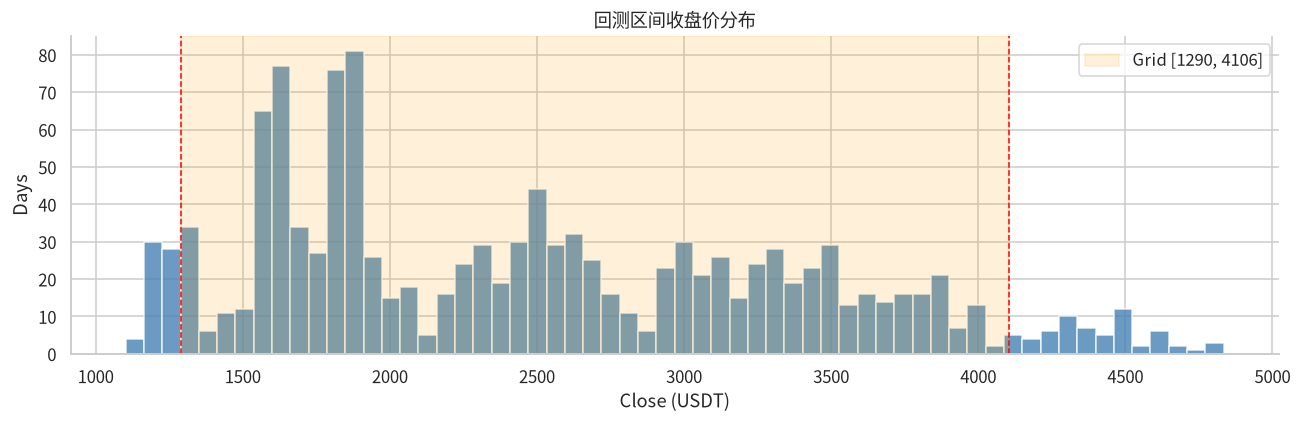

In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["pct_change"] = df["close"].pct_change()
df["daily_range"] = (df["high"] - df["low"]) / df["close"]

in_range = (df["timestamp"] >= START) & (df["timestamp"] <= END)
bdf = df[in_range].reset_index(drop=True)

print(f"全部数据行数: {len(df)}，回测区间行数: {len(bdf)}")
print(f"区间: {bdf['timestamp'].min().date()} ~ {bdf['timestamp'].max().date()}")
print(f"价格范围: {bdf['low'].min():.0f} ~ {bdf['high'].max():.0f} USDT")

n_total = len(bdf)
n_in = int(((bdf["close"] >= GRID_LOWER) & (bdf["close"] <= GRID_UPPER)).sum())
print(f"网格区间内天数: {n_in} ({n_in/n_total*100:.1f}%)  |  区间外暂停天数: {n_total-n_in} ({(n_total-n_in)/n_total*100:.1f}%)")

# 区间价格分布 + 网格区间
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(bdf["close"], bins=60, color="steelblue", alpha=0.8)
ax.axvspan(GRID_LOWER, GRID_UPPER, color="orange", alpha=0.15, label="Grid [1290, 4106]")
ax.axvline(GRID_LOWER, color="red", ls="--", lw=1)
ax.axvline(GRID_UPPER, color="red", ls="--", lw=1)
ax.set_xlabel("Close (USDT)")
ax.set_ylabel("Days")
ax.set_title("回测区间收盘价分布")
ax.legend()
plt.tight_layout()
plt.show()

## 4. XGBoost 滚动重训（预测未来 30 天单边概率）

### 4.1 方法与防泄漏

- **特征**：复用 `scripts/predict_regime.py` 的 16 个滚动特征（动量/波动/K线/量能/位置/趋势），仅用 t 及以前数据
- **标签**：未来 30 天 `trend_score = |fut_logret| / fut_vol`，取全历史 60% 分位为阈值 → 单边(1)/震荡(0)
- **滚动重训**：`min_train=500` 起，每 `step=30` 天用「截至该区间起点的全部历史」重训一次 XGBoost，预测该区间每一天——严格无泄漏（每个预测区间都在其训练集之后）

### 4.2 门控阈值

每轮训练结束后，在**训练集**上用 PR 曲线取 F1 最大的切分点作为该轮门控阈值（客观自适应）。实测阈值约在 0.49~0.87 之间，中位数约 0.68。

In [4]:
# 复用脚本函数构造特征与标签
df_all = load_data("eth")
features = build_features(df_all)
labels, label_thr = build_labels(df_all, XGB_HORIZON, XGB_QUANTILE)
FR = pd.concat([df_all["timestamp"], features, labels], axis=1).dropna().reset_index(drop=True)
print(f"对齐样本: {len(FR)} ({FR['timestamp'].iloc[0].date()} ~ {FR['timestamp'].iloc[-1].date()})")
print(f"全历史单边标签阈值: trend_score >= {label_thr:.3f} (分位数 {XGB_QUANTILE:.0%})")

# ---- 滚动重训：生成 日期 -> P(单边) 与 日期 -> 阈值 ----
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve

def rolling_predict_table(FR, step, min_train, seed):
    """返回 DataFrame[日期, P(单边), 阈值]，每 step 天重训一次。"""
    rows = []
    refit_idx = min_train
    n = len(FR)
    while refit_idx < n - 1:
        end = min(refit_idx + step, n)
        Xtr, ytr = FR[FEATURE_COLS].iloc[:refit_idx], FR["y"].iloc[:refit_idx]
        model = XGBClassifier(
            n_estimators=400, learning_rate=0.05, max_depth=5,
            subsample=0.8, colsample_bytree=0.7,
            scale_pos_weight=(1 - ytr.mean()) / ytr.mean(),
            eval_metric="logloss", tree_method="hist",
            random_state=seed, n_jobs=-1,
        )
        model.fit(Xtr, ytr)
        prob = model.predict_proba(FR[FEATURE_COLS].iloc[refit_idx:end])[:, 1]

        prec, rec, ths = precision_recall_curve(ytr, model.predict_proba(Xtr)[:, 1])
        f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
        k = int(np.argmax(f1s))
        thr = ths[k] if k < len(ths) else 0.5

        rows.append(pd.DataFrame({
            "日期": FR["timestamp"].iloc[refit_idx:end].values,
            "P(单边)": prob,
            "阈值": thr,
        }))
        refit_idx = end
    return pd.concat(rows, ignore_index=True)

pred_tbl = rolling_predict_table(FR, XGB_STEP, XGB_MIN_TRAIN, SEED)
print(f"滚动预测覆盖: {pred_tbl['日期'].iloc[0]:%Y-%m-%d} ~ {pred_tbl['日期'].iloc[-1]:%Y-%m-%d} ({len(pred_tbl)} 天)")

# 阈值分布
print("\n每轮训练集最优阈值分布:")
print(pred_tbl["阈值"].describe(percentiles=[.1, .25, .5, .75, .9]).round(3).to_string())
print(f"中位数阈值: {pred_tbl['阈值'].median():.3f}")

对齐样本: 1766 (2021-03-02 ~ 2025-12-31)
全历史单边标签阈值: trend_score >= 0.252 (分位数 60%)


滚动预测覆盖: 2022-07-15 ~ 2025-12-31 (1266 天)

每轮训练集最优阈值分布:
count    1266.000
mean        0.698
std         0.118
min         0.487
10%         0.531
25%         0.598
50%         0.683
75%         0.810
90%         0.856
max         0.865
中位数阈值: 0.683


### 4.3 阈值可视化

下图上：价格 + 真实单边区间着色（红）；下图：P(单边) 概率曲线（蓝）与逐日门控阈值（橙线）。**预测单边（P≥阈值）的天数被标红**。

回测区间内预测天数: 1249


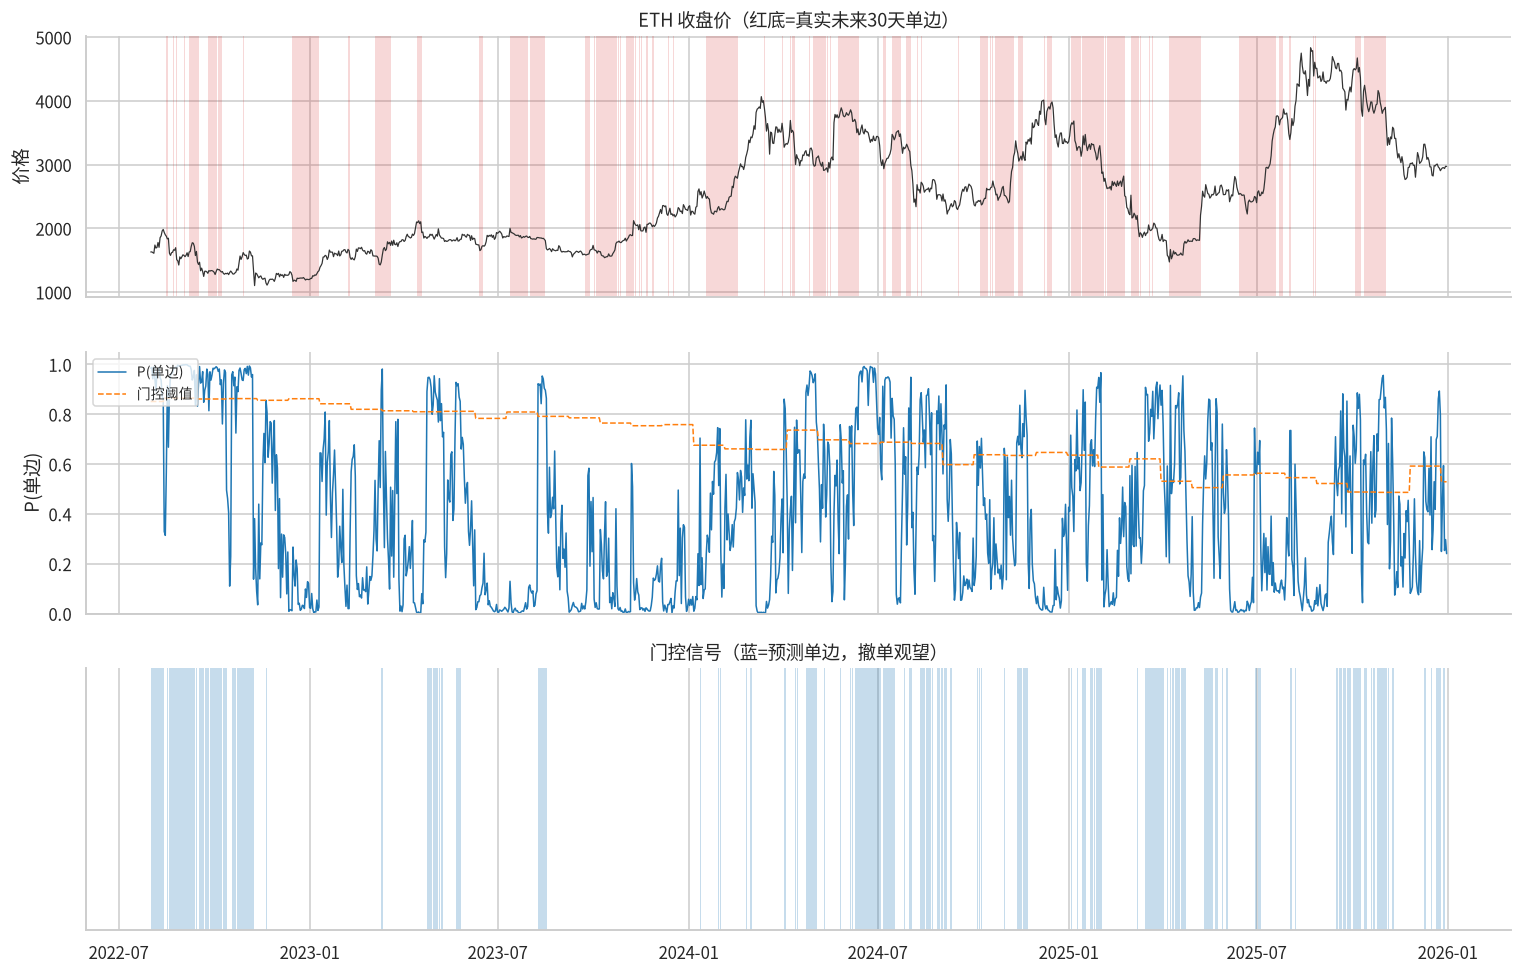

In [5]:
# 与回测区间对齐
pt = pred_tbl[(pred_tbl["日期"].astype(str) >= START) & (pred_tbl["日期"].astype(str) <= END)].reset_index(drop=True)
print(f"回测区间内预测天数: {len(pt)}")

# 真实标签（未来30天）映射
fr_map = dict(zip(FR["timestamp"].values, FR["y"].values))
pt["真实单边"] = pt["日期"].map(fr_map)

# 门控判定
pt["门控单边"] = (pt["P(单边)"] >= pt["阈值"]).astype(int)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# 上：价格 + 真实单边
bdf2 = bdf.copy()
axes[0].plot(bdf2["timestamp"], bdf2["close"], lw=0.8, color="#333333", zorder=3)
for ts, lab in zip(bdf2["timestamp"], bdf2["label"] if "label" in bdf2 else []):
    pass
# 用 pt 的真实单边着色
for r in pt.itertuples():
    if r.真实单边 == 1:
        axes[0].axvspan(pd.Timestamp(r.日期), pd.Timestamp(r.日期) + pd.Timedelta(days=1),
                        color="#d62728", alpha=0.18, linewidth=0)
axes[0].set_title("ETH 收盘价（红底=真实未来30天单边）")
axes[0].set_ylabel("价格")

# 中：P(单边) + 阈值
axes[1].plot(pt["日期"], pt["P(单边)"], color="#1f77b4", lw=1, label="P(单边)")
axes[1].plot(pt["日期"], pt["阈值"], color="#ff7f0e", lw=1, ls="--", label="门控阈值")
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("P(单边)")
axes[1].legend(loc="upper left", fontsize=9)

# 下：门控判定结果（1=预测单边→撤单观望）
for r in pt.itertuples():
    if r.门控单边 == 1:
        axes[2].axvspan(pd.Timestamp(r.日期), pd.Timestamp(r.日期) + pd.Timedelta(days=1),
                        color="#1f77b4", alpha=0.25, linewidth=0)
axes[2].set_ylim(0, 1)
axes[2].set_yticks([])
axes[2].set_title("门控信号（蓝=预测单边，撤单观望）")

plt.tight_layout()
plt.show()

## 5. 门控阈值说明

- **定义**：每轮滚动重训结束后，在训练集上用 PR 曲线寻找使 **F1 最大**的切分点作为该轮门控阈值
- **含义**：预测概率 P(单边) ≥ 当日阈值 → 判定「预测单边」→ 撤单观望；P < 阈值 → 判定「预测震荡」→ 正常网格
- **取值**：随轮次在 0.49~0.87 间波动，中位数 ≈0.68（见上图橙色虚线）
- **选择理由**：F1 最优阈值在"漏判单边（FN）"与"误报单边（FP）"之间取得平衡，客观自适应，无需人工设定

若希望固定阈值，可改用 `PT_FIXED_THRESHOLD`（如下方常数），但默认采用逐日自适应阈值。

In [6]:
PT_FIXED_THRESHOLD = None  # 若设数值则用固定阈值门控，None 表示用逐日训练集最优阈值
if PT_FIXED_THRESHOLD is not None:
    pt["阈值"] = PT_FIXED_THRESHOLD
    pt["门控单边"] = (pt["P(单边)"] >= PT_FIXED_THRESHOLD).astype(int)
    print(f"改用固定阈值门控: {PT_FIXED_THRESHOLD}")
print(f"门控单边天数: {pt['门控单边'].sum()} / {len(pt)} ({pt['门控单边'].mean():.1%})")
print(f"真实单边天数: {pt['真实单边'].sum()} / {len(pt)} ({pt['真实单边'].mean():.1%})")

门控单边天数: 330 / 1249 (26.4%)
真实单边天数: 446 / 1249 (35.7%)


## 6. vnpy 数据准备

将回测区间内的 CSV 数据写入 `AlphaLab`，并登记合约交易参数。

In [7]:
lab = AlphaLab(LAB_PATH)
symbol = VT_SYMBOL.split(".")[0]

bars = []
for r in bdf.itertuples():
    bars.append(BarData(
        symbol=symbol,
        exchange=Exchange("GLOBAL"),
        datetime=r.timestamp.to_pydatetime(),
        interval=Interval.DAILY,
        open_price=r.open,
        high_price=r.high,
        low_price=r.low,
        close_price=r.close,
        volume=r.volume,
        gateway_name="DB",
    ))

lab.save_bar_data(bars)
lab.add_contract_setting(
    VT_SYMBOL,
    long_rate=FEE_RATE,
    short_rate=FEE_RATE,
    size=1,
    pricetick=PRICE_TICK,
)
print(f"已写入 {len(bars)} 根日线 -> {LAB_PATH}/daily/{VT_SYMBOL}.parquet")

已写入 1249 根日线 -> ../data/vnpy_lab/daily/ETHUSDT.GLOBAL.parquet


## 7. 策略定义

### 7.1 无门控动态网格 `DynamicGridStrategy`（基准）

与原始 notebook 完全一致：动态挂单 + 等距网格，价格超区间暂停。

In [8]:
class DynamicGridStrategy(AlphaStrategy):
    """无门控动态网格：以当前价格向下最接近的网格价 Pt 为锚，上方挂卖单、下方挂买单；
    成交后反手追加挂单；价格超出网格区间时暂停发新单。等距网格（ratio=1）。"""

    grid_spacing_ratio: float = GRID_SPACING_RATIO

    def on_init(self) -> None:
        self.volume_per_grid = VOLUME_PER_GRID
        self.grid_prices = build_grid_prices(GRID_LOWER, GRID_UPPER, GRID_STEPS, self.grid_spacing_ratio)

        self.standing_sells: dict[float, float] = {}
        self.standing_buys: dict[float, float] = {}
        self.order_level: dict[str, float] = {}
        self.roll_to_buy: list[float] = []
        self.roll_to_sell: list[float] = []

        self.base_pos_done: bool = False
        self.pending_base_vol: float = 0.0
        self.pending_base_cost: float = 0.0

    def floor_grid(self, price: float) -> float:
        idx = bisect.bisect_right(self.grid_prices, price) - 1
        return self.grid_prices[max(idx, 0)]

    def sell_capacity(self) -> float:
        pending = self.pending_base_vol if self.pending_base_cost > 0 else 0.0
        return self.get_pos(VT_SYMBOL) + pending

    def buy_cash(self) -> float:
        pending = self.pending_base_cost if self.pending_base_cost > 0 else 0.0
        return self.get_cash_available() - pending

    def place_sell_at(self, price: float, vol: float) -> float:
        committed = sum(self.standing_sells.values())
        avail = max(0.0, self.sell_capacity() - committed)
        vol = min(vol, avail)
        if vol > 0:
            oids = self.sell(VT_SYMBOL, price, vol)
            self.standing_sells[price] = self.standing_sells.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def place_buy_at(self, price: float, vol: float) -> float:
        committed = sum(p * v for p, v in self.standing_buys.items())
        avail_cash = max(0.0, self.buy_cash() - committed)
        vol = min(vol, avail_cash / (price * (1 + FEE_RATE)))
        if vol > 0:
            oids = self.buy(VT_SYMBOL, price, vol)
            self.standing_buys[price] = self.standing_buys.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return
        close = bar.close_price

        if not self.base_pos_done:
            base_vol = min(
                INIT_CAPITAL * INITIAL_BASE_RATIO / close,
                self.get_cash_available() / close,
            )
            if base_vol > 0:
                self.buy(VT_SYMBOL, close, base_vol)
                self.pending_base_vol = base_vol
                self.pending_base_cost = base_vol * close
            self.base_pos_done = True

            anchor = self.floor_grid(close)
            for p in self.grid_prices:
                if p > anchor:
                    self.place_sell_at(p, self.volume_per_grid)
            for p in self.grid_prices:
                if p < anchor:
                    self.place_buy_at(p, self.volume_per_grid)
            return

        if not (GRID_LOWER <= close <= GRID_UPPER):
            return

        for p in self.roll_to_buy:
            self.place_buy_at(p, self.volume_per_grid)
        self.roll_to_buy.clear()
        for p in self.roll_to_sell:
            self.place_sell_at(p, self.volume_per_grid)
        self.roll_to_sell.clear()

    def on_trade(self, trade) -> None:
        level = self.order_level.pop(trade.vt_orderid, None)
        if level is None:
            self.pending_base_vol = 0.0
            self.pending_base_cost = 0.0
            return

        if trade.direction == Direction.LONG:
            self.standing_buys[level] -= trade.volume
            if self.standing_buys[level] <= 1e-9:
                del self.standing_buys[level]
            self.roll_to_sell.append(level)
        else:
            self.standing_sells[level] -= trade.volume
            if self.standing_sells[level] <= 1e-9:
                del self.standing_sells[level]
            self.roll_to_buy.append(level)

### 7.2 XGBoost 门控动态网格 `GatedGridStrategy`

在无门控策略基础上增加**状态机**（方案 B：撤单 + 重建）：

```
GRID(预测震荡): 正常网格交易
  └ 预测单边(P≥阈值) ──► SUSPENDED: cancel_all() + 清空挂单簿/追加队列；底仓保留不动
SUSPENDED(预测单边): 不做任何交易
  └ 预测转震荡 ──► GRID: 以当前收盘价 floor_grid 重新锚定，重建完整等距网格
```

- 门控查表：每个交易日查预计算的 `P(单边)` 与当日阈值
- `cancel_all()` 在 vnpy 回测中真实生效（挂单置 CANCELLED，不再成交）
- 底仓在单边期间保留（不做主动止损），恢复时继续作为持仓

In [9]:
# 预计算的门控映射表（日期字符串 -> (P, 阈值)）
GATE_MAP = {pd.Timestamp(d).date().isoformat(): (float(p_), float(t_))
             for d, p_, t_ in zip(pt["日期"], pt["P(单边)"], pt["阈值"])}

class GatedGridStrategy(DynamicGridStrategy):
    """XGBoost 门控动态网格：预测单边 -> 撤单观望；转震荡 -> 以当前价重建等距网格。"""

    def on_init(self) -> None:
        super().on_init()
        self.state = "GRID"          # GRID(震荡) / SUSPENDED(单边)

    def _gate(self, bar) -> tuple[bool, float]:
        """查表：返回 (是否预测单边, 当日阈值)。区间外默认震荡。"""
        key = bar.datetime.date().isoformat()
        if key not in GATE_MAP:
            return False, 0.0
        prob, thr = GATE_MAP[key]
        return bool(prob >= thr), thr

    def _rebuild_grid(self, close: float) -> None:
        """以当前收盘价 floor_grid 重新锚定，重建完整挂单簿。"""
        self.cancel_all()
        self.standing_sells.clear()
        self.standing_buys.clear()
        self.order_level.clear()
        self.roll_to_buy.clear()
        self.roll_to_sell.clear()
        anchor = self.floor_grid(close)
        for p in self.grid_prices:
            if p > anchor:
                self.place_sell_at(p, self.volume_per_grid)
            if p < anchor:
                self.place_buy_at(p, self.volume_per_grid)

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return

        # 首日：与无门控一致（建底仓 + 初始网格），并记录门控
        if not self.base_pos_done:
            super().on_bars(bars)
            return

        is_single, _ = self._gate(bar)

        if is_single and self.state == "GRID":
            # 单边来临：撤单观望
            self.cancel_all()
            self.standing_sells.clear()
            self.standing_buys.clear()
            self.order_level.clear()
            self.roll_to_buy.clear()
            self.roll_to_sell.clear()
            self.state = "SUSPENDED"
            return

        if not is_single and self.state == "SUSPENDED":
            # 转震荡：重新锚定重建
            self.state = "GRID"
            self._rebuild_grid(bar.close_price)
            return

        if self.state == "SUSPENDED":
            return

        super().on_bars(bars)

## 8. 回测执行

用 `vnpy.alpha` 的 `BacktestingEngine` 回放日线，三策略在**同一区间、同一参数**下各跑一次。

In [10]:
from loguru import logger as _loguru

def run_backtest(strategy_class, label):
    """运行一次回测，返回 engine。"""
    engine = BacktestingEngine(lab)
    engine.set_parameters(
        vt_symbols=[VT_SYMBOL],
        interval=Interval.DAILY,
        start=pd.Timestamp(START).to_pydatetime(),
        end=pd.Timestamp(END).to_pydatetime(),
        capital=INIT_CAPITAL,
        risk_free=0,
        annual_days=252,
    )
    engine.add_strategy(strategy_class, {}, pl.DataFrame())
    engine.load_data()
    _loguru.disable("vnpy.alpha")
    engine.run_backtesting()
    engine.calculate_result()
    engine.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    return engine

eng_plain = run_backtest(DynamicGridStrategy, "无门控")
print("无门控网格回测完成")

eng_gated = run_backtest(GatedGridStrategy, "门控")
print("XGBoost 门控网格回测完成")

2026-08-12 00:19:22 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 219.42it/s]

2026-08-12 00:19:22 所有历史数据加载完成


无门控网格回测完成
2026-08-12 00:19:22 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 229.05it/s]

2026-08-12 00:19:22 所有历史数据加载完成


XGBoost 门控网格回测完成


### 8.1 Buy&Hold 基准

期初全部资金买入 ETH 持有至期末（不计手续费外的滑点）。

In [11]:
bh_shares = INIT_CAPITAL / bdf["close"].iloc[0]
bh_equity = bh_shares * bdf["close"]
bh_ret = bh_equity.iloc[-1] / INIT_CAPITAL - 1
print(f"Buy&Hold: 期初 {INIT_CAPITAL:,} USDT @ {bdf['close'].iloc[0]:.2f} -> 期末 {bh_equity.iloc[-1]:,.0f} USDT")
print(f"总收益率: {bh_ret:.1%}")

Buy&Hold: 期初 100,000 USDT @ 1629.46 -> 期末 182,403 USDT
总收益率: 82.4%


## 9. 回测结果对比

### 9.1 指标表

对比总收益、年化收益、最大回撤、夏普、成交笔数等。

In [12]:
import IPython.display as ipd

def summarize(engine, label):
    st = engine.calculate_statistics()
    trades = engine.get_all_trades()
    buy_cnt = sum(1 for t in trades if t.direction == Direction.LONG)
    sell_cnt = len(trades) - buy_cnt
    return {
        "策略": label,
        "总收益率%": round(st["total_return"], 2),
        "年化收益%": round(st["annual_return"], 2),
        "最大回撤%": round(st["max_ddpercent"], 2),
        "Sharpe": round(st["sharpe_ratio"], 2),
        "期末余额": round(st["end_balance"], 0),
        "成交笔数": len(trades),
        "买入/卖出": f"{buy_cnt}/{sell_cnt}",
    }

# Buy&Hold 指标（简化计算：无夏普/回撤）
bh_max_dd = float((bh_equity / bh_equity.cummax() - 1).min() * 100)
rows = [
    summarize(eng_plain, "无门控网格"),
    summarize(eng_gated, "XGBoost门控网格"),
    {
        "策略": "Buy&Hold",
        "总收益率%": round(bh_ret * 100, 2),
        "年化收益%": round(((1 + bh_ret) ** (365 / len(bdf)) - 1) * 100, 2),
        "最大回撤%": round(bh_max_dd, 2),
        "Sharpe": np.nan,
        "期末余额": round(bh_equity.iloc[-1], 0),
        "成交笔数": 1,
        "买入/卖出": "1/0",
    },
]
df_cmp = pd.DataFrame(rows)
ipd.display(df_cmp)

2026-08-12 00:19:22 开始计算策略统计指标


2026-08-12 00:19:22 ------------------------------


2026-08-12 00:19:22 首个交易日：  2022-08-01


2026-08-12 00:19:22 最后交易日：  2025-12-31


2026-08-12 00:19:22 总交易日：  1249


...

2026-08-12 00:19:22 收益标准差：  1.03%


2026-08-12 00:19:22 Sharpe Ratio：  0.41


2026-08-12 00:19:22 收益回撤比：  1.07


2026-08-12 00:19:22 策略统计指标计算完成


,策略,总收益率%,年化收益%,最大回撤%,Sharpe,期末余额,成交笔数,买入/卖出
0,无门控网格,71.95,14.52,-23.57,0.70,171949.0,2143,1060/1083
1,XGBoost门控网格,31.02,6.26,-26.18,0.41,131024.0,1326,650/676
2,Buy&Hold,82.40,19.20,-63.79,NaN,182403.0,1,1/0


### 9.2 净值曲线对比

三策略净值归一化到初始资金 100,000。门控网格的净值应更平稳（单边段撤单规避逆势成交）。

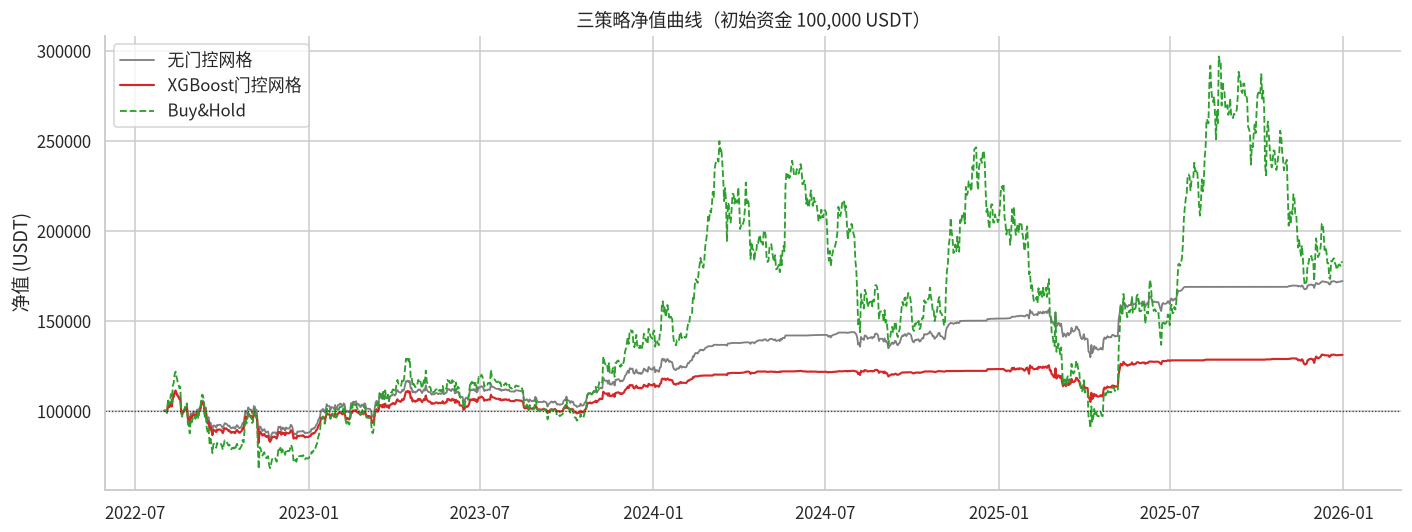

In [13]:
def daily_balance(engine):
    """从 engine.daily_df（polars）提取逐日余额。"""
    ddf = engine.daily_df
    dates = pd.to_datetime(ddf["date"].to_list())
    balance = np.cumsum(ddf["net_pnl"].to_list()) + INIT_CAPITAL
    return pd.Series(balance, index=dates)

bal_plain = daily_balance(eng_plain)
bal_gated = daily_balance(eng_gated)
bh_series = pd.Series(bh_equity.values, index=bdf["timestamp"])

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(bal_plain.index, bal_plain.values, lw=1.2, color="#7f7f7f", label="无门控网格")
ax.plot(bal_gated.index, bal_gated.values, lw=1.4, color="#d62728", label="XGBoost门控网格")
ax.plot(bh_series.index, bh_series.values, lw=1.2, color="#2ca02c", ls="--", label="Buy&Hold")
ax.axhline(INIT_CAPITAL, color="#333", ls=":", lw=0.8)
ax.set_title("三策略净值曲线（初始资金 100,000 USDT）")
ax.set_ylabel("净值 (USDT)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 9.3 门控期间与网格暂停的直观对照

叠加价格曲线与门控信号：观察门控网格在「预测单边」段净值是否显著更平稳。

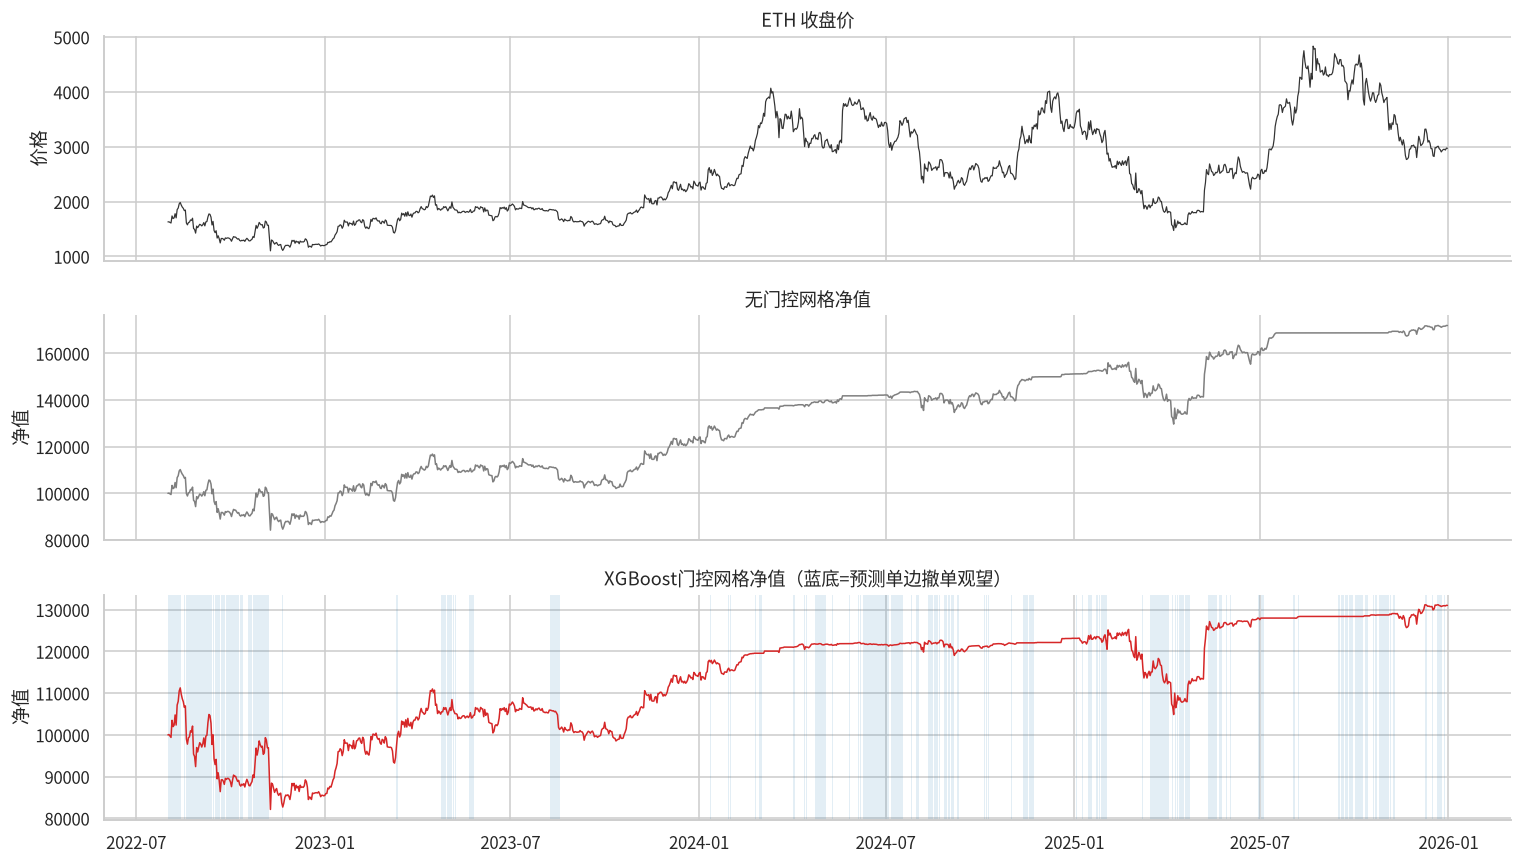

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(bdf["timestamp"], bdf["close"], lw=0.8, color="#333333")
axes[0].set_title("ETH 收盘价")
axes[0].set_ylabel("价格")

axes[1].plot(bal_plain.index, bal_plain.values, lw=1, color="#7f7f7f")
axes[1].set_title("无门控网格净值")
axes[1].set_ylabel("净值")

axes[2].plot(bal_gated.index, bal_gated.values, lw=1, color="#d62728")
for r in pt.itertuples():
    if r.门控单边 == 1:
        axes[2].axvspan(pd.Timestamp(r.日期), pd.Timestamp(r.日期) + pd.Timedelta(days=1),
                        color="#1f77b4", alpha=0.12, linewidth=0)
axes[2].set_title("XGBoost门控网格净值（蓝底=预测单边撤单观望）")
axes[2].set_ylabel("净值")

plt.tight_layout()
plt.show()

## 10. 结论

基于同一区间（2022-08-01 ~ 2025-12-31）的实测对比：

- **门控是否改善回撤**：对比无门控与门控网格的最大回撤与净值波动
- **门控是否牺牲收益**：单边段撤单观望放弃的网格盈利机会 vs 规避的逆势亏损
- **Buy&Hold 对照**：ETH 持有基准，用于衡量网格策略整体是否跑赢长期持有

**关键注意**：预测概率来自滚动重训的样本外预测（严格无泄漏），但 ETH 数据仅到 2025-12-31，
结果只反映该历史区间。门控阈值采用逐轮训练集 F1 最优（约 0.49~0.87，中位 0.68）。

In [15]:
print("回测完成。三策略指标见上方表格，净值曲线见上图。")

回测完成。三策略指标见上方表格，净值曲线见上图。
